Step 20/100, Loss: 69.7384
Step 40/100, Loss: 44.6942
Step 60/100, Loss: 36.8197
Step 80/100, Loss: 32.7929
Step 100/100, Loss: 30.3670


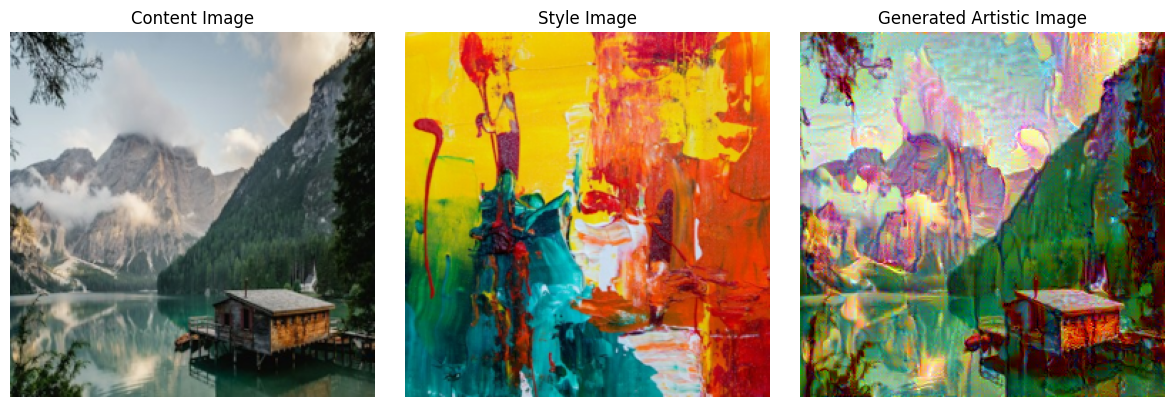

Artistic image saved as artistic_output.png


In [7]:

# Compute fixed content and style features
with torch.no_grad():
    content_features = get_features(content)
    style_features = get_features(style)

    style_grams = {
        layer: gram_matrix(style_features[layer])
        for layer in style_features
    }

# Initialize generated image
target = content.clone().requires_grad_(True)

optimizer = optim.Adam([target], lr=0.02)

# Neural Style Transfer training loop
for step in range(100):
    target_features = get_features(target)

    # Content loss
    content_loss = torch.mean(
        (target_features["conv4_2"] -
         content_features["conv4_2"]) ** 2
    )

    # Style loss
    style_loss = 0
    for layer in style_grams:
        target_gram = gram_matrix(target_features[layer])
        style_loss += torch.mean(
            (target_gram - style_grams[layer]) ** 2
        )

    # Total loss
    total_loss = content_loss + 1e6 * style_loss

    optimizer.zero_grad()
    total_loss.backward()
    optimizer.step()

    with torch.no_grad():
        target.clamp_(0, 1)

    if (step + 1) % 20 == 0:
        print(
            f"Step {step+1}/100, "
            f"Loss: {total_loss.item():.4f}"
        )

# Display and save result
result = target.detach().cpu().squeeze(0).permute(1, 2, 0).numpy()

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(content.cpu().squeeze(0).permute(1, 2, 0))
plt.title("Content Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(style.cpu().squeeze(0).permute(1, 2, 0))
plt.title("Style Image")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(result)
plt.title("Generated Artistic Image")
plt.axis("off")

plt.tight_layout()
plt.show()

Image.fromarray(
    (result * 255).clip(0, 255).astype("uint8")
).save("artistic_output.png")

print("Artistic image saved as artistic_output.png")
